# Threat Detection and Response System

# Project Overview

This project aims to develop a threat detection and response system by leveraging machine learning and natural language processing (NLP) techniques. The system classifies emails as spam or non-spam using a publicly available dataset and integrates the model into communication platforms to identify and mitigate potential threats.

# 1. Data Collection
The dataset used for this project was sourced from Kaggle, which contains labeled spam and non-spam emails. This dataset serves as the foundation for training and evaluating the threat detection model.
### Sources
2007 TREC Public Spam Corpus
Original link: https://plg.uwaterloo.ca/~gvcormac/treccorpus07/
Preprocessed download link: https://www.kaggle.com/datasets/bayes2003/emails-for-spam-or-ham-classification-trec-2007
Enron-Spam Dataset
Original link: https://www2.aueb.gr/users/ion/data/enron-spam/
Preprocessed download link: https://github.com/MWiechmann/enron_spam_data/
Code for combining and processing the two datasets: https://github.com/PuruSinghvi/Spam-Email-Classifier/blob/main/Combining%20Datasets.ipynb

The Email Spam dataset is a collection of Email messages that are labeled as either “spam” or “ham” (non-spam). The dataset contains 83,448 Emails, of which 39,538 are labeled as ham and 43,910 as spam. The dataset is publicly available on Kaggle, which is a platform that hosts machine learning datasets and competitions.

## Importing the necessary Python libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [2]:
# Read data using pandas
data = pd.read_csv("combined_data.csv")
#print first five rows of data
print(data.head()) 

   label                                               text
0      1  ounce feather bowl hummingbird opec moment ala...
1      1  wulvob get your medircations online qnb ikud v...
2      0   computer connection from cnn com wednesday es...
3      1  university degree obtain a prosperous future m...
4      0  thanks for all your answers guys i know i shou...


### We only have the email text data and label from the dataset. So let's select both the columns and move furthur:

In [3]:
data = data[["label", "text"]]
print(data.head())

   label                                               text
0      1  ounce feather bowl hummingbird opec moment ala...
1      1  wulvob get your medircations online qnb ikud v...
2      0   computer connection from cnn com wednesday es...
3      1  university degree obtain a prosperous future m...
4      0  thanks for all your answers guys i know i shou...


### The label column contains values 0 and 1. 0 indicates legitimate / not spam emails and 1 indicates phishing / spam emails. So to make it look better, I will use spam and not spam labels instead of 1 and 0:

In [4]:
data["label"] = data["label"].map({0: "Not Spam", 1: "Spam Email"})
print(data.sample(5))

            label                                               text
43556    Not Spam  on escapenumber escapenumber escapenumber mehm...
10053    Not Spam  on escapenumber escapenumber escapenumber usen...
18494  Spam Email  hi brand new escapenumber replica models expre...
12365  Spam Email   i moved from escapenumber across the hail thi...
73553    Not Spam  hi i've been searching for a solution to this ...


In [5]:
data.shape

(83448, 2)

There are 83,448 emails nd 2 columns present in the dataset.

In [6]:
# Count the occurrences of each label in the dataset
label_counts = data['label'].value_counts()

In [7]:
# Print the number of spam and non-spam messages
print("Number of Spam Emails:", label_counts['Spam Email'])
print("Number of Non-Spam Emails:", label_counts['Not Spam'])

# Alternatively, you can print the whole distribution
print("\nLabel Distribution:")
print(label_counts)

Number of Spam Emails: 43910
Number of Non-Spam Emails: 39538

Label Distribution:
label
Spam Email    43910
Not Spam      39538
Name: count, dtype: int64


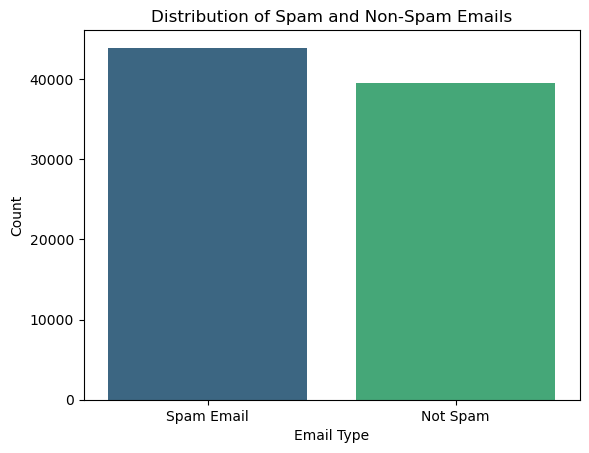

In [12]:
# Count the occurrences of each label in the dataset
label_counts = data['label'].value_counts()

# Plot the bar chart
sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')
plt.title('Distribution of Spam and Non-Spam Emails')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.show()


Spam emails are more than ham emails.

# 2. Data Preprocessing
### Techniques Used:

•	Tokenization: The text data was split into individual tokens (words) using the nltk.tokenize module, which helps in breaking down the email content for further analysis.

•	Lemmatization: Words were normalized to their base form using nltk.stem.WordNetLemmatizer, ensuring that different forms of a word are treated equivalently (e.g., "running" to "run").

•	Removal of Stop-Words: Common words that do not contribute to the classification, such as "and," "the," and "is," were removed using the nltk.corpus.stopwords list, reducing noise in the data.

•	Regular Expressions: The re module was employed to clean the text further by removing unwanted characters, numbers, and punctuations, ensuring that only relevant textual data is retained.


In [9]:
#Checking null values
null_values = data.isnull().sum()
print(null_values)

label    0
text     0
dtype: int64


There are no null values in this dataset.

In [10]:
#Checcking duplicated values
duplicate_rows = data[data.duplicated()]
print(duplicate_rows)

Empty DataFrame
Columns: [label, text]
Index: []


There are no duplicated emails in the dataset.

In [4]:
# Define function to preprocess the text
def preprocess_text(txt):
    txt = re.sub(r'\W', ' ', txt)
    txt = txt.lower()
    stop_words = set(stopwords.words('english'))
    word_tokens = word_tokenize(txt)
    filtered_text = [word for word in word_tokens if word not in stop_words]
    ps = PorterStemmer()
    stemmed_text = [ps.stem(word) for word in filtered_text]
    return ' '.join(stemmed_text)
data['text'] = data['text'].apply(preprocess_text)
print(data.head())

   label                                               text
0      1  ounc feather bowl hummingbird opec moment alab...
1      1  wulvob get medirc onlin qnb ikud viagra escape...
2      0  comput connect cnn com wednesday escapenumb ma...
3      1  univers degre obtain prosper futur money earn ...
4      0  thank answer guy know check rsync manual would...


# 3. Feature Extraction
### Method:
•	CountVectorizer: The CountVectorizer function from the sklearn.feature_extraction.text module was used to convert the text data into a matrix of token counts. This transformation allows the machine learning models to interpret the text data numerically, making it possible to classify the emails.This dataset has two columns, out of which the “text” column as a feature and the “label” column as a label. So let’s select these columns and split the data into 20% test set and 80% training set:

In [9]:
# Define x and y variables
X = data['text']
y = data['label']

# Split the data into training and test sets
X_train1, X_test1, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
#Iniitialize the CountVectorizer
vectorizer = CountVectorizer()

# Fit and transform the text data
X_train = vectorizer.fit_transform(X_train1)
X_test = vectorizer.transform(X_test1)

In [11]:
X_train

<66758x235800 sparse matrix of type '<class 'numpy.int64'>'
	with 6086709 stored elements in Compressed Sparse Row format>

In [12]:
y_train

9381     Spam Email
11566      Not Spam
40822      Not Spam
35045      Not Spam
38667      Not Spam
            ...    
6265       Not Spam
54886      Not Spam
76820      Not Spam
860        Not Spam
15795      Not Spam
Name: label, Length: 66758, dtype: object

# 4. Model Development
### Algorithms Used:
#### i. Multinomial Naive Bayes:
A probabilistic model particularly suited for text classification tasks, utilizing the frequencies of words to predict the likelihood of an email being spam.
#### ii. Decision Tree Classifier: 
A tree-based model that splits the data into subsets based on the most significant features, helping to classify the emails.
#### iii. Random Forest Classifier: 
An ensemble method that builds multiple decision trees and combines their predictions to improve accuracy and reduce overfitting.

# 5. Model Evaluation
### Metrics:
####  •	The performance of the models was evaluated using the following metrics:
#### o	Accuracy: 
The proportion of correctly classified emails.
#### o	Precision: 
The ratio of correctly predicted spam emails to the total predicted as spam.
#### o	Recall: 
The ratio of correctly predicted spam emails to all actual spam emails.
#### o	F1-Score: 
The harmonic mean of precision and recall, providing a balanced measure of model performance.
# 6. Model Optimization
### Techniques:
#### •	Hyperparameter Tuning:
The models were optimized by tuning hyperparameters such as the smoothing parameter for the Naive Bayes model, the depth of the decision trees, and the number of trees in the random forest, . This process involved experimenting with different configurations to identify the best-performing model.


## i. Naive Bayes classifier

In [19]:
clf = MultinomialNB()
clf.fit(X_train, y_train)

MultinomialNB()

In [20]:
y_pred_train = clf.predict(X_train)
y_pred_test = clf.predict(X_test)

In [21]:
train_accuracy = accuracy_score(y_train, y_pred_train)
train_precision = precision_score(y_train, y_pred_train, average='weighted')
train_recall = recall_score(y_train, y_pred_train, average='weighted')
train_f1 = f1_score(y_train, y_pred_train, average='weighted')
train_confusion = confusion_matrix(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)
test_precision = precision_score(y_test, y_pred_test, average='weighted')
test_recall = recall_score(y_test, y_pred_test, average='weighted')
test_f1 = f1_score(y_test, y_pred_test, average='weighted')
test_confusion = confusion_matrix(y_test, y_pred_test)

print(f"Training Accuracy: {train_accuracy}")
print(f"Training Precision: {train_precision}")
print(f"Training Recall: {train_recall}")
print(f"Training F1 Score: {train_f1}")
print("Training Confusion Matrix:")
print(train_confusion)

Training Accuracy: 0.9822493184337457
Training Precision: 0.9823296727784125
Training Recall: 0.9822493184337457
Training F1 Score: 0.9822543500149066
Training Confusion Matrix:
[[31207   393]
 [  792 34366]]


In [22]:
print(f"\nTesting Accuracy: {test_accuracy}")
print(f"Testing Precision: {test_precision}")
print(f"Testing Recall: {test_recall}")
print(f"Testing F1 Score: {test_f1}")
print("Testing Confusion Matrix:")
print(test_confusion)


Testing Accuracy: 0.9760934691431995
Testing Precision: 0.9764037467464338
Testing Recall: 0.9760934691431995
Testing F1 Score: 0.9761041283175468
Testing Confusion Matrix:
[[7840   98]
 [ 301 8451]]


## ii. Decision Tree

In [ ]:
# Define the parameter grid
param_grid = {
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize the model and GridSearchCV
dt = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1, n_jobs=-1)

# Fit the GridSearchCV object
grid_search.fit(X_train, y_train)

# Retrieve the best parameters
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Use the best parameters to train a new model
best_dt_regressor = DecisionTreeClassifier(**best_params)
best_dt_regressor.fit(X_train, y_train)


In [ ]:
y_pred_train = best_dt_regressor.predict(X_train)
y_pred_test = best_dt_regressor.predict(X_test)

In [ ]:
train_accuracy = accuracy_score(y_train, y_pred_train)
train_precision = precision_score(y_train, y_pred_train, average='weighted')
train_recall = recall_score(y_train, y_pred_train, average='weighted')
train_f1 = f1_score(y_train, y_pred_train, average='weighted')
train_confusion = confusion_matrix(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)
test_precision = precision_score(y_test, y_pred_test, average='weighted')
test_recall = recall_score(y_test, y_pred_test, average='weighted')
test_f1 = f1_score(y_test, y_pred_test, average='weighted')
test_confusion = confusion_matrix(y_test, y_pred_test)

print(f"Training Accuracy: {train_accuracy}")
print(f"Training Precision: {train_precision}")
print(f"Training Recall: {train_recall}")
print(f"Training F1 Score: {train_f1}")
print("Training Confusion Matrix:")
print(train_confusion)

In [ ]:
print(f"\nTesting Accuracy: {test_accuracy}")
print(f"Testing Precision: {test_precision}")
print(f"Testing Recall: {test_recall}")
print(f"Testing F1 Score: {test_f1}")
print("Testing Confusion Matrix:")
print(test_confusion)

## iii. Random Forest

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf_classifier = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf_classifier, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1, n_jobs=-1)
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)
best_rf_regressor = RandomForestClassifier(**best_params)
best_rf_regressor.fit(X_train, y_train)

Fitting 5 folds for each of 81 candidates, totalling 405 fits


In [ ]:
y_pred_train = best_rf_regressor.predict(X_train)
y_pred_test = best_rf_regressor.predict(X_test)

In [ ]:
train_accuracy = accuracy_score(y_train, y_pred_train)
train_precision = precision_score(y_train, y_pred_train, average='weighted')
train_recall = recall_score(y_train, y_pred_train, average='weighted')
train_f1 = f1_score(y_train, y_pred_train, average='weighted')
train_confusion = confusion_matrix(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)
test_precision = precision_score(y_test, y_pred_test, average='weighted')
test_recall = recall_score(y_test, y_pred_test, average='weighted')
test_f1 = f1_score(y_test, y_pred_test, average='weighted')
test_confusion = confusion_matrix(y_test, y_pred_test)

print(f"Training Accuracy: {train_accuracy}")
print(f"Training Precision: {train_precision}")
print(f"Training Recall: {train_recall}")
print(f"Training F1 Score: {train_f1}")
print("Training Confusion Matrix:")
print(train_confusion)

In [ ]:
print(f"\nTesting Accuracy: {test_accuracy}")
print(f"Testing Precision: {test_precision}")
print(f"Testing Recall: {test_recall}")
print(f"Testing F1 Score: {test_f1}")
print("Testing Confusion Matrix:")
print(test_confusion)

## Model Comparison

In [13]:
models = {
    "Naive Bayes" : MultinomialNB(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}
results = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    test_precision = precision_score(y_test, y_pred_test, average='weighted')
    test_recall = recall_score(y_test, y_pred_test, average='weighted')
    test_f1 = f1_score(y_test, y_pred_test, average='weighted')
    
    results.append({
        "Model": model_name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Test Precision": test_precision,
        "Test Recall": test_recall,
        "Test F1 Score": test_f1
    })
results_df = pd.DataFrame(results)
results_df

,Model,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1 Score
0,Naive Bayes,0.982249,0.976093,0.976404,0.976093,0.976104
1,Random Forest,0.999880,0.980407,0.980553,0.980407,0.980414
2,Decision Tree,0.999880,0.961354,0.961381,0.961354,0.961359


## Conclusion
Random Forest shows excellent performance with high accuracy on both training and test sets. The precision, recall, and F1 score are all very close to each other, indicating a well-balanced model that performs consistently well on the test data.

# 7. Integration Framework
### Proposal:
•	A framework is proposed for integrating the best-performing model into various communication platforms. This integration aims to enable real-time detection and classification of emails, enhancing the system's ability to identify and respond to potential threats effectively.


In [ ]:
from IPython.display import Image
Image(filename='/kaggle/input/spam-detction/Screenshot 2024-06-18 142454.png')

### Now let’s use a sample email text as input to test whether our machine learning model detects spam or not:

In [8]:
sample = "Check this out:https://kaggle.com/"
data = vectorizer.transform([sample]).toarray()
print(rf_classifier.predict(data))

[0]


In [10]:
sample = "thank you"
data = vectorizer.transform([sample]).toarray()
print(rf_classifier.predict(data))

['Not Spam']


## Automated Response

### After executing the below command, the system will ask for user input and will provide output about email whether its legitimate or phishing as not spam or spam:

In [17]:
user = input("Enter an Email Text: ")
data = vectorizer.transform([user]).toarray()
output = rf_classifier.predict(data)
print(output)

Enter an Email Text: Congratulations! You've won a prize.
['Spam Email']


In [18]:
user = input("Enter an Email Text: ")
data = vectorizer.transform([user]).toarray()
output = rf_classifier.predict(data)
print(output)

Enter a Text: hi paliourg , our online shop is your source for locating many prescription drugs without a prior prescription in compliance with fda regulations . valium 10 mg - [ 60 pills $ 279 . 99 ] [ 90 pills $ 329 . 99 ] [ 120 pills $ 369 . 99 ] xanax 1 mg - [ 30 pills $ 169 . 00 ] [ 60 pills $ 229 . 00 ] [ 90 pills $ 269 . 00 ] [ 120 pills $ 309 . 99 ] vicodin ( hydrocodone / apapl 0 mg / 500 mg ) - [ 30 pills $ 159 . 99 ] [ 60 pills $ 249 . 99 ] [ 90 pills $ 319 . 99 ] [ 90 pills $ 289 . 99 ] [ 60 pills $ 289 . 99 ] viagra 50 mg [ 20 pills $ 99 . 99 ] [ 40 pills $ 149 . 99 ] [ 120 pills $ 269 . 99 ] [ 200 pills $ 349 . 99 ] viagra 100 mg [ 20 pills $ 119 . 99 ] [ 40 pills $ 179 . 99 ] [ 120 pills $ 349 . 99 ] [ 200 pills $ 449 . 99 ] carisoprodol ( soma ) [ 60 pills $ 79 . 99 ] [ 90 pills $ 99 . 99 ] phentermine 15 mg [ 60 pills $ 139 . 00 ] [ 180 pills $ 249 . 00 ] adipex 37 . 5 mg [ 30 pills $ 149 . 00 ] [ 90 pills $ 299 . 00 ] [ 60 pills $ 229 . 00 ] tramadol 50 mg [ 30 pills 

In [26]:
user = input("Enter an Email Text: ")
data = vectorizer.transform([user]).toarray()
output = rf_classifier.predict(data)
print(output)

Enter a Text: hi i have this error tr sample escapenumber escapenumber escapenumber train rbind irisescapenumber tr escapenumber irisescapenumber tr escapenumber
['Not Spam']


In [10]:
user = input("Enter an Email Text: ")
data = vectorizer.transform([user]).toarray()
output = rf_classifier.predict(data)
print(output)

Enter an Email Text: thank you
['Not Spam']


In [9]:
# import pickle
# #create a pickle (byte) file to save the vectorizer object for later use
# pickle.dump(cv, open('cv.pkl','wb'))
# #save the Decision Tree Classifier Model Object as pickle file
# pickle.dump(clf, open('clf.pkl','wb'))

In [1]:
import dash
from dash import html, dcc, Input, Output, State

In [11]:
# Initialize the Dash app
app = dash.Dash(__name__)

# Define the layout of the app
app.layout = html.Div([
    html.Div([
        html.H1("Threat Detection and Response System", style={'text-align': 'center'}),
        
        html.Div([
            dcc.Textarea(id='email_text', placeholder='Enter Email Text',
                      style={'margin': '10px', 'padding': '10px'}),
#             dcc.Input(id='num_convenience_stores', type='number', placeholder='Number of Convenience Stores',
#                       style={'margin': '10px', 'padding': '10px'}),
#             dcc.Input(id='latitude', type='number', placeholder='Latitude',
#                       style={'margin': '10px', 'padding': '10px'}),
#             dcc.Input(id='longitude', type='number', placeholder='Longitude',
#                       style={'margin': '10px', 'padding': '10px'}),
            html.Button('Output', id='predict_button', n_clicks=0,
                        style={'margin': '10px', 'padding': '10px', 'background-color': '#007BFF', 'color': 'white'}),
        ], style={'text-align': 'center'}),
        
        html.Div(id='prediction_output', style={'text-align': 'center', 'font-size': '20px', 'margin-top': '20px'})
    ], style={'width': '50%', 'margin': '0 auto', 'border': '2px solid #007BFF', 'padding': '20px', 'border-radius': '10px'})
])

# Define callback to update output
@app.callback(
    Output('prediction_output', 'children'),
    [Input('predict_button', 'n_clicks')],
    [State('email_text', 'value')]
)
def update_output(n_clicks, email_text):
    if n_clicks > 0 and email_text:
        # Preprocess the input text
        processed_text = preprocess_text(email_text)  # Use the existing clean function here
        # Transform the text using the vectorizer
        features = vectorizer.transform([processed_text])
        # Predict
        prediction = rf_classifier.predict(features)[0]
        # Determine the label based on the prediction
        if prediction == 1:
            label = "Spam Email"
        else:
            label = "Not Spam"
        return f'The email is classified as: {label}'
    elif n_clicks > 0:
        return 'Please enter the email text to get a prediction'
    return ''


# Run the app
if __name__ == '__main__':
    app.run_server(debug=True)

In [19]:
# import imaplib
# import email
# from email.header import decode_header
# import pandas as pd
# from sklearn.feature_extraction.text import CountVectorizer
# from sklearn.naive_bayes import MultinomialNB

# # Example classifier and vectorizer (replace with your own)
# cv = CountVectorizer()  # Initialize the vectorizer
# clf = MultinomialNB()  # Initialize the classifier

# def fetch_emails(email_user, email_password):
#     # Connect to the server
#     mail = imaplib.IMAP4_SSL('imap.gmail.com')  # Use your email provider's IMAP server
#     mail.login(email_user, email_password)
    
#     # Select the mailbox you want to use
#     mail.select('inbox')
    
#     # Search for all emails
#     status, messages = mail.search(None, 'ALL')
#     email_ids = messages[0].split()
    
#     emails = []
    
#     for email_id in email_ids:
#         status, msg_data = mail.fetch(email_id, '(RFC822)')
#         msg = email.message_from_bytes(msg_data[0][1])
#         subject = decode_header(msg["Subject"])[0][0]
#         if isinstance(subject, bytes):
#             subject = subject.decode()
#         body = msg.get_payload(decode=True).decode()
#         emails.append((subject, body))
    
#     mail.logout()
#     return emails

# def classify_emails(emails):
#     data = pd.DataFrame(emails, columns=['Subject', 'Body'])
#     data['Text'] = data['Subject'] + " " + data['Body']
#     features = cv.transform(data['Text'])
#     predictions = clf.predict(features)
#     data['Classification'] = ['Spam' if p == 1 else 'Not Spam' for p in predictions]
#     return data


In [12]:
# import dash
# from dash import html, dcc, Input, Output, State
# import pandas as pd

# # Initialize the Dash app
# app = dash.Dash(__name__)

# # Define the layout of the app
# app.layout = html.Div([
#     html.H1("Email Spam Classification", style={'text-align': 'center'}),
    
#     html.Div([
#         dcc.Input(id='email_user', type='text', placeholder='Email User'),
#         dcc.Input(id='email_password', type='password', placeholder='Email Password'),
#         html.Button('Fetch and Classify Emails', id='fetch_button', n_clicks=0),
#     ], style={'text-align': 'center'}),
    
#     html.Div(id='email_table', style={'text-align': 'center', 'margin-top': '20px'})
# ])

# # Define callback to update output
# @app.callback(
#     Output('email_table', 'children'),
#     [Input('fetch_button', 'n_clicks')],
#     [State('email_user', 'value'), State('email_password', 'value')]
# )
# def update_output(n_clicks, email_user, email_password):
#     if n_clicks > 0 and email_user and email_password:
#         # Fetch and classify emails
#         emails = fetch_emails(email_user, email_password)
#         classified_emails = classify_emails(emails)
        
#         # Create a table to display emails
#         return html.Div([
#             html.H4("Classified Emails"),
#             html.Table([
#                 html.Thead(
#                     html.Tr([html.Th(col) for col in classified_emails.columns])
#                 ),
#                 html.Tbody([
#                     html.Tr([html.Td(classified_emails.iloc[i][col]) for col in classified_emails.columns])
#                     for i in range(len(classified_emails))
#                 ])
#             ])
#         ])
#     elif n_clicks > 0:
#         return 'Please enter email credentials to fetch and classify emails'
#     return ''

# import os

# email_user = os.getenv('EMAIL_USER')
# email_password = os.getenv('EMAIL_PASSWORD')


# # Run the app
# if __name__ == '__main__':
#     app.run_server(debug=True)
    
    
